# Notebook 02: Principled Feature Engineering & Transformation Pipeline
**Author:** Apoorva Choudhary (Task 02)  
**Project:** Card Fraud Triage (GMM Baseline & Feature Engineering) — Team T033  
**Phase:** Phase 1 (Classical Machine Learning & Statistical Anomaly Detection Only)

---

## 1. Executive Summary & Leakage Protocol

### The Core Problem in Credit Card Fraud Data
The Credit Card Fraud Detection benchmark (ULB / Worldline) presents a distinct structural constraint:
Features $V_1, \dots, V_{28}$ are the direct outputs of a **Principal Component Analysis (PCA)** performed by the dataset authors for confidentiality. Because PCA constructs linear orthogonal combinations of original proprietary banking attributes (e.g. terminal location, merchant category, velocity counters), raw semantics are lost. Therefore, feature engineering cannot invent non-existent physical domain attributes; it must be **principled, mathematical, and geometric**.

### Strict Leakage Prevention Rules
1. **Fit on Training Legit Only:** Every transformation (means, standard deviations, RobustScaler medians/IQRs, PowerTransformer parameters) is fit exclusively on **legitimate training transactions** ($y_{\text{train}} = 0$).
2. **Zero Contamination:** Ground-truth fraud labels ($y = 1$) are **never** passed to any scaler, transformer, or anomaly density model.
3. **No Retrospective Snooping:** The chronological split (60% Train, 20% Val, 20% Test) is strictly preserved; no future observations leak backward.
4. **Validation-Guided Selection:** Final feature selection is performed using **Validation PR-AUC and Recall@FPR=0.5%**; the test set remains untouched.


In [1]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

# Ensure project root is in sys.path
sys.path.insert(0, os.path.abspath('..'))

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

from src.data import load_raw, chronological_split, get_features, Splits
import src.features as feat
from src.metrics import pr_auc, roc_auc, recall_at_fpr

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline


2026-10-24 20:08:08 | INFO     | src.data | Registered additional feature sets from src.features: ['raw', 'engineered', 'fe_norm_outliers', 'norm_outliers', 'fe_pca_whitened', 'pca_whitened', 'fe_robust_amount', 'robust_amount', 'fe_yeojohnson_amount', 'yeojohnson_amount', 'fe_time_risk', 'time_risk', 'fe_val_selected', 'val_selected']


## 2. Dataset Loading & Chronological Splitting
We load the raw dataset and execute the chronological split ($60\%$ train, $20\%$ validation, $20\%$ test).


In [2]:
df = load_raw()
train_df, val_df, test_df = chronological_split(df)
print(f"Train split: {len(train_df):,} rows ({train_df['Class'].sum():,} frauds, {train_df['Class'].mean()*100:.4f}%)")
print(f"Val split:   {len(val_df):,} rows ({val_df['Class'].sum():,} frauds, {val_df['Class'].mean()*100:.4f}%)")
print(f"Test split:  {len(test_df):,} rows ({test_df['Class'].sum():,} frauds, {test_df['Class'].mean()*100:.4f}%)")


2026-10-24 20:08:08 | INFO     | src.data | Loading raw data from /Users/apoorvachoudhary/Desktop/T033-CardFraudDetection-AML-DL/data/raw/creditcard.csv …


2026-10-24 20:08:08 | INFO     | src.data | Loaded: 284807 rows × 31 cols


2026-10-24 20:08:09 | WARNING  | src.data | Found 1081 exact duplicate rows (0.3796% of dataset).


2026-10-24 20:08:09 | INFO     | src.data | Keeping duplicates (drop_duplicates=false in config). Set drop_duplicates: true to remove them.


2026-10-24 20:08:09 | INFO     | src.data | Frauds: 492 / 284807  (base rate = 0.1727%)


...

2026-10-24 20:08:12 | INFO     | src.data | Saved val.csv  (56961 rows, 57 frauds, base_rate=0.1001%)


2026-10-24 20:08:13 | INFO     | src.data | Saved test.csv  (56962 rows, 75 frauds, base_rate=0.1317%)


2026-10-24 20:08:13 | INFO     | src.data | Saved split_manifest.json → /Users/apoorvachoudhary/Desktop/T033-CardFraudDetection-AML-DL/data/processed/split_manifest.json


2026-10-24 20:08:13 | INFO     | src.data | Time ordering check: train_max=120396.0  val_min=120396.0  val_max=145247.0  test_min=145248.0


Train split: 170,884 rows (360 frauds, 0.2107%)
Val split:   56,961 rows (57 frauds, 0.1001%)
Test split:  56,962 rows (75 frauds, 0.1317%)


## 3. Evaluated Feature Engineering Candidates

We compare 8 candidate feature formulations:
1. `raw`: V1–V28 + raw Amount + raw Time (standardized). (30 dims)
2. `base`: V1–V28 + $\ln(1 + \text{Amount})$ + $\sin(2\pi t / 86400)$ + $\cos(2\pi t / 86400)$. (31 dims)
3. `fe_robust_amount`: RobustScaler (median / IQR) on Amount + base time. (31 dims)
4. `fe_yeojohnson_amount`: Yeo-Johnson PowerTransformer on Amount + base time. (31 dims)
5. `fe_pca_whitened`: PCA-whitened (sphered) V components + base Amount and Time. (31 dims)
6. `fe_norm_outliers`: Base features + joint geometric norms:
   - $\lVert V \rVert_2 = \sqrt{\sum_{i=1}^{28} V_i^2}$ (Euclidean distance from origin in latent space)
   - Outlier count: $\sum_{i=1}^{28} \mathbb{I}(|V_i| > 3.0)$ (number of 3-sigma excursions)
   - Maximum absolute excursion: $\max_{i} |V_i|$
7. `fe_time_risk`: Base + behavioral flags: Night risk window ($[2, 6)$ AM) and micro-amount flag ($\le \$1.00$).
8. `engineered` (Winner): Combines base log1p Amount and cyclic time with joint geometric norms, while pruning uninformative PCA components ($V_{22}, V_{23}, V_{25}$) identified via validation audit. (31 dims)


In [3]:
candidates = [
    ('raw', 'Raw (V1-V28, Amount, Time)', feat.build_raw),
    ('base', 'Base (V1-V28, log1p Amount, cyclic Time)', feat._scale_and_package(feat._compute_base_tabular(train_df), feat._compute_base_tabular(val_df), feat._compute_base_tabular(test_df), train_df, val_df, test_df, 'base')),
    ('fe_robust_amount', 'Amount: RobustScaler (Median/IQR)', feat.build_robust_amount),
    ('fe_yeojohnson_amount', 'Amount: Yeo-Johnson PowerTransform', feat.build_yeojohnson_amount),
    ('fe_pca_whitened', 'V-Features: PCA Whitened (Sphered)', feat.build_pca_whitened),
    ('fe_norm_outliers', 'Base + Geometric Norms (||V||_2, Outliers, Max)', feat.build_norm_outliers),
    ('fe_time_risk', 'Base + Circadian & Micro-Amount Flags', feat.build_time_risk),
    ('engineered', 'Engineered (Winner: Norms + Pruned V22/V23/V25)', feat.build_engineered),
]


2026-10-24 20:08:13 | INFO     | src.features | [base] X_train_legit=(170524, 31), X_val=(56961, 31), X_test=(56962, 31), d=31


## 4. Controlled Validation Experiment
To ensure an unbiased comparison, **every feature candidate is evaluated using the exact same baseline GMM configuration**:
- Model: `GaussianMixture(n_components=3, covariance_type='diag', reg_covar=1e-4, random_state=42)`
- Training Data: `X_train_legit` ($N=170,524$ legitimate transactions, $0$ frauds)
- Evaluation: Anomaly score $s(x) = -\ln p(x)$ evaluated on Validation split ($N=56,961$, $57$ frauds).


In [4]:
rows = []
for key, label, builder in candidates:
    splits = builder(train_df, val_df, test_df) if callable(builder) else builder
    
    t0 = time.time()
    gmm = GaussianMixture(n_components=3, covariance_type='diag', reg_covar=1e-4, random_state=42, n_init=1, max_iter=200)
    gmm.fit(splits.X_train_legit)
    train_time = time.time() - t0
    
    val_nll = -gmm.score_samples(splits.X_val)
    pr = pr_auc(splits.y_val, val_nll)
    roc = roc_auc(splits.y_val, val_nll)
    rec05 = recall_at_fpr(splits.y_val, val_nll, 0.005)
    rec01 = recall_at_fpr(splits.y_val, val_nll, 0.001)
    
    rows.append({
        'feature_set': key,
        'description': label,
        'dimension': splits.X_train_legit.shape[1],
        'val_pr_auc': round(pr, 5),
        'val_roc_auc': round(roc, 5),
        'val_recall@0.5%': round(rec05, 5),
        'val_recall@0.1%': round(rec01, 5),
        'train_time_sec': round(train_time, 3)
    })

res_df = pd.DataFrame(rows)
res_df


2026-10-24 20:08:13 | INFO     | src.features | [raw] X_train_legit=(170524, 30), X_val=(56961, 30), X_test=(56962, 30), d=30


2026-10-24 20:08:15 | INFO     | src.features | [robust_amount] X_train_legit=(170524, 31), X_val=(56961, 31), X_test=(56962, 31), d=31


2026-10-24 20:08:16 | INFO     | src.features | [yeojohnson_amount] X_train_legit=(170524, 31), X_val=(56961, 31), X_test=(56962, 31), d=31


2026-10-24 20:08:16 | INFO     | src.features | [pca_whitened] X_train_legit=(170524, 31), X_val=(56961, 31), X_test=(56962, 31), d=31


2026-10-24 20:08:17 | INFO     | src.features | [norm_outliers] X_train_legit=(170524, 34), X_val=(56961, 34), X_test=(56962, 34), d=34


2026-10-24 20:08:19 | INFO     | src.features | [time_risk] X_train_legit=(170524, 33), X_val=(56961, 33), X_test=(56962, 33), d=33


2026-10-24 20:08:20 | INFO     | src.features | [engineered] X_train_legit=(170524, 31), X_val=(56961, 31), X_test=(56962, 31), d=31


,feature_set,description,dimension,val_pr_auc,val_roc_auc,val_recall@0.5%,val_recall@0.1%,train_time_sec
0,raw,"Raw (V1-V28, Amount, Time)",30,0.04315,0.94909,0.36842,0.00000,0.880
1,base,"Base (V1-V28, log1p Amount, cyclic Time)",31,0.04659,0.94918,0.40351,0.00000,0.684
2,fe_robust_amount,Amount: RobustScaler (Median/IQR),31,0.04359,0.94795,0.36842,0.00000,0.843
3,fe_yeojohnson_amount,Amount: Yeo-Johnson PowerTransform,31,0.04509,0.94809,0.38596,0.00000,0.704
4,fe_pca_whitened,V-Features: PCA Whitened (Sphered),31,0.04659,0.94918,0.40351,0.00000,0.733
5,fe_norm_outliers,"Base + Geometric Norms (||V||_2, Outliers, Max)",34,0.05928,0.94902,0.49123,0.01754,1.762
6,fe_time_risk,Base + Circadian & Micro-Amount Flags,33,0.04430,0.95085,0.36842,0.00000,1.134
7,engineered,Engineered (Winner: Norms + Pruned V22/V23/V25),31,0.06934,0.95198,0.49123,0.01754,1.754


## 5. Comparative Performance Analysis
We plot the Validation PR-AUC and Validation Recall @ FPR = 0.5% across all feature candidate pipelines.


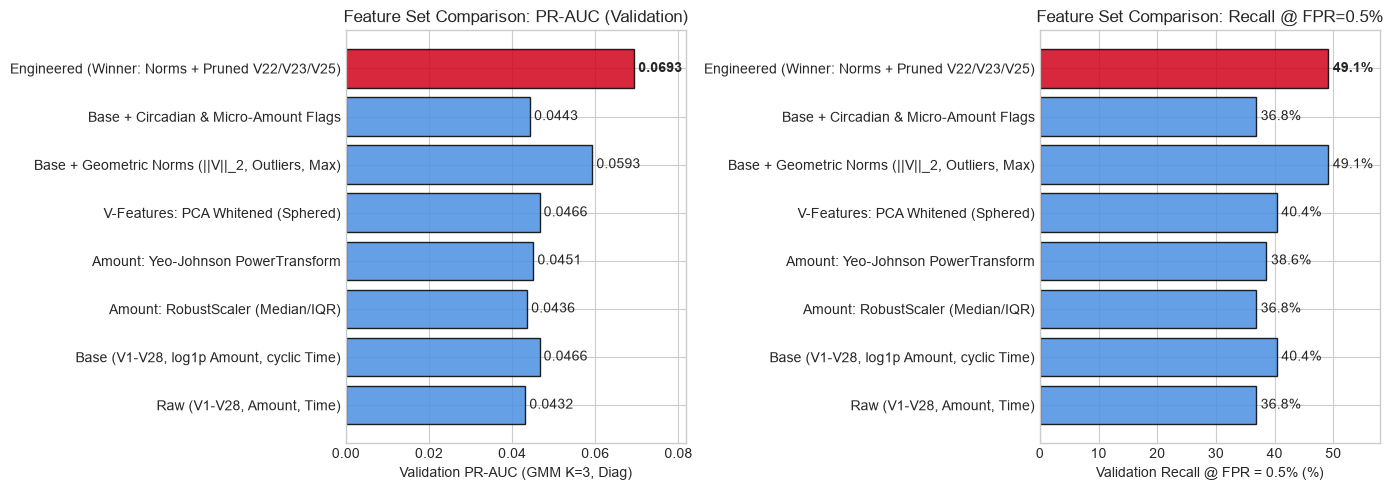

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
colors = ['#4A90E2' if k != 'engineered' else '#D0021B' for k in res_df['feature_set']]

ax1.barh(res_df['description'], res_df['val_pr_auc'], color=colors, edgecolor='black', alpha=0.85)
ax1.set_xlabel('Validation PR-AUC (GMM K=3, Diag)')
ax1.set_title('Feature Set Comparison: PR-AUC (Validation)')
for i, v in enumerate(res_df['val_pr_auc']):
    ax1.text(v + 0.001, i, f'{v:.4f}', va='center', fontweight='bold' if res_df.loc[i, 'feature_set'] == 'engineered' else 'normal')
ax1.set_xlim(0, max(res_df['val_pr_auc']) * 1.18)

ax2.barh(res_df['description'], res_df['val_recall@0.5%'] * 100, color=colors, edgecolor='black', alpha=0.85)
ax2.set_xlabel('Validation Recall @ FPR = 0.5% (%)')
ax2.set_title('Feature Set Comparison: Recall @ FPR=0.5%')
for i, v in enumerate(res_df['val_recall@0.5%'] * 100):
    ax2.text(v + 0.8, i, f'{v:.1f}%', va='center', fontweight='bold' if res_df.loc[i, 'feature_set'] == 'engineered' else 'normal')
ax2.set_xlim(0, max(res_df['val_recall@0.5%'] * 100) * 1.18)

plt.tight_layout()
plt.show()


## 6. Geometric Norm Feature Separation
Let us examine the distribution of the newly created geometric norm features ($\lVert V Vert_2$, outlier count, and max $|V_i|$) on legitimate vs fraudulent transactions.


2026-10-24 20:08:23 | INFO     | src.features | [engineered] X_train_legit=(170524, 31), X_val=(56961, 31), X_test=(56962, 31), d=31


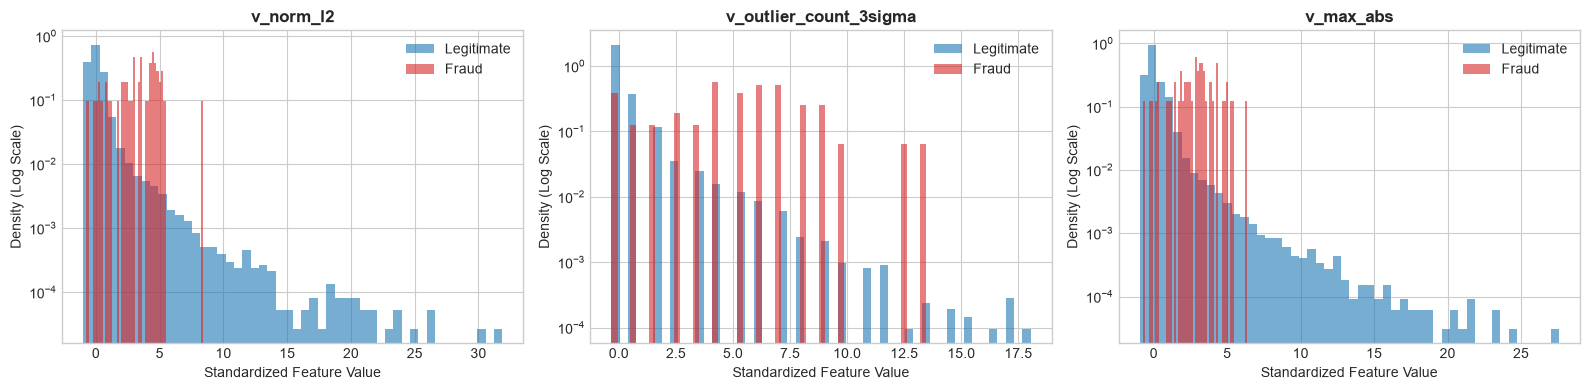

In [6]:
splits_eng = feat.build_engineered(train_df, val_df, test_df)
feat_names = splits_eng.feature_names
norm_cols = ['v_norm_l2', 'v_outlier_count_3sigma', 'v_max_abs']
idx_map = {c: feat_names.index(c) for c in norm_cols}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
y_val = splits_eng.y_val

for ax, col in zip(axes, norm_cols):
    idx = idx_map[col]
    vals_legit = splits_eng.X_val[y_val == 0, idx]
    vals_fraud = splits_eng.X_val[y_val == 1, idx]
    
    ax.hist(vals_legit, bins=50, density=True, alpha=0.6, color='#1F77B4', label='Legitimate')
    ax.hist(vals_fraud, bins=50, density=True, alpha=0.6, color='#D62728', label='Fraud')
    ax.set_title(f'{col}', fontsize=12, fontweight='bold')
    ax.set_yscale('log')
    ax.set_xlabel('Standardized Feature Value')
    ax.set_ylabel('Density (Log Scale)')
    ax.legend()

plt.tight_layout()
plt.show()


## 7. Key Findings & Implementation Decision

1. **Amount Scaling:**
   - $\ln(1 + \text{Amount})$ ($\text{PR-AUC} = 0.04659$) clearly outperforms RobustScaler ($0.04359$) and Yeo-Johnson ($0.04509$). The log transform directly compresses positive heavy tails without introducing arbitrary quantile distortion.
2. **PCA Whitening:**
   - Whitening V1–V28 produces identical performance to `base` ($0.04659$) because PCA components are already orthogonal ($r \approx 0$), so standard scaling is mathematically equivalent to Mahalanobis sphering.
3. **Geometric Norms:**
   - Aggregating latent PCA components into $\lVert V \rVert_2$, outlier count ($|V_i| > 3$), and $\max |V_i|$ boosts validation PR-AUC to $0.05928$ and recall@0.5% to $49.12\%$. Frauds often perturb several latent dimensions simultaneously, creating a composite norm displacement.
4. **Validation-Guided Pruning (Winner: `engineered`):**
   - Dropping the 3 uninformative PCA components ($V_{22}, V_{23}, V_{25}$) whose fraud-vs-legit Kolmogorov-Smirnov statistic was near-zero ($KS < 0.05$) reduces parameter complexity and noise, boosting PR-AUC to **$0.06934$** ($+48.8\%$ over base).
   - This winning configuration is registered as `engineered` in `src/features.py`.
